# **Introduction**
**Authors: Hassan Faris & Travis Gubbe**

The goal of this project is to create a machine learning model to determine and predict the prices of used vehicles in the United States based on different vehicle characteristics. The data set acquired is from Kaggle, with over 550,000 data entries across 16 variables. Our focus for this project is to understand how a used vehicle's characteristics such as milage, condition, make, body type, transmission, color and age are related to selling price and how well our model uses these variables to predict the selling price.


# **Import/Inspect Data**

Connects Google Drive to Colab

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Imported libraries that will be useful

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns

The data is imported into Colab

Travis' file path

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Datasets/car_prices.csv')

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Datasets/car_prices.csv'

Hassan's file path

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Stat585/car_prices.csv')

The data is viewed to give a quick look. A quick view gives a sense of data types and the formatting of the data. MMR and selling price seem to be very similar in number, and sale date has a date format that can be suitable for a breakdown of a vehicle's sale date compared to manufacture year.

In [ ]:
df.head()

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,Thu Dec 18 2014 12:30:00 GMT-0800 (PST)


Calculates the total NA (or missing) values for each column. There's more missing transmissions compared to any other column, but this may not have too large of an impact on the model since it's expected that a large majority of vehicles in the United States will have automatic transmissions. Missing condition and make may impact the model if these are significant variables, since certain vehicle makes and better conditioned vehicles may be more desirable to consumers. Having more of this data may help with a more accurate model of selling price for used vehicles.

In [ ]:
df.isna().sum()

,0
year,0
make,10301
model,10399
trim,10651
body,13195
transmission,65352
vin,4
state,0
condition,11820
odometer,94


The shape gives the amount of observations (558,837) and columns (16).

In [ ]:
df.shape

(558837, 16)

Quick summary statistics for the numeric variables. There may be outliers present in the odometer variable (999,999 miles). There is also a selling price of a vehicle of \$1, which may indicate a typo or a vehicle severely damaged or undesirable and sold at a minimum. The max selling price of \$230,000 indicates there is at least one luxury vehicle present in the data. It may be beneficial to get a count of vehicle types to see how many luxury vehicles are present.

In [ ]:
df.describe()

,year,condition,odometer,mmr,sellingprice
count,558837.000000,547017.000000,558743.000000,558799.000000,558825.000000
mean,2010.038927,30.672365,68320.017767,13769.377495,13611.358810
std,3.966864,13.402832,53398.542821,9679.967174,9749.501628
min,1982.000000,1.000000,1.000000,25.000000,1.000000
25%,2007.000000,23.000000,28371.000000,7100.000000,6900.000000
50%,2012.000000,35.000000,52254.000000,12250.000000,12100.000000
75%,2013.000000,42.000000,99109.000000,18300.000000,18200.000000
max,2015.000000,49.000000,999999.000000,182000.000000,230000.000000


# **Exploratory Data Analysis**

Before model creation, Exploratory Data Analysis (EDA) is performed to better understand the data set and relationships between explanatory variables and selling price for used vehicles. In addition, EDA will help identify the identify any concerning observations as well as potential groupings of categorical variables.

A histogram of the selling price. Majority of vehicles are between \$0 and \$50,000. The distribution appears right-skewed and may need a transformation before modeling. A log-transformation helps standardize a right-skewed distribution, compressing the extreme values at the far end and expanding the very small values to create a more balanced distribution.

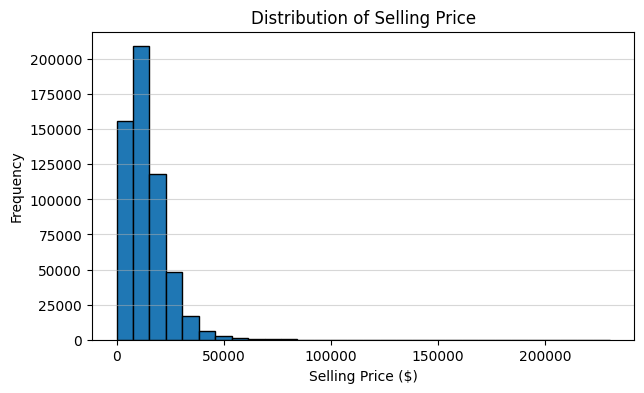

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(df['sellingprice'], bins = 30, edgecolor='black')
plt.title('Distribution of Selling Price')
plt.xlabel('Selling Price ($)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.5)
plt.show()

A histogram of the odometer variable (mileage) for all vehicles. Like selling price, the data appears right-skewed and a transformation should be investigated before modeling the data.

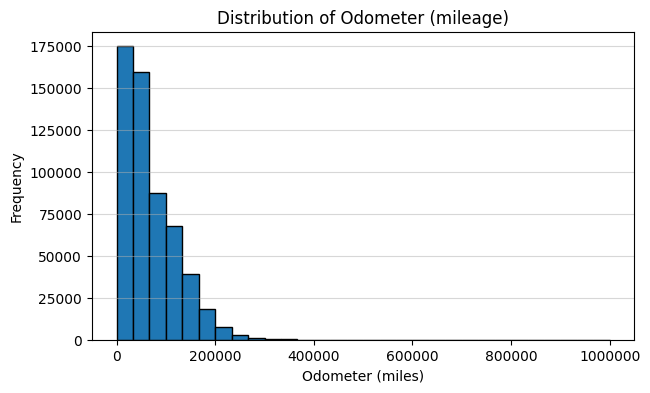

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(df['odometer'], bins = 30, edgecolor='black')
plt.title('Distribution of Odometer (mileage)')
plt.xlabel('Odometer (miles)')
plt.ylabel('Frequency')
plt.ticklabel_format(style = "plain", axis = "both")
plt.grid(axis='y', alpha=0.5)
plt.show()

Correlation matrix of the numeric variables, displaying the strength of relationship between the target variable (selling price) and potential independent variables. From the results, there appears to be multicollinearity between MMR and selling price, which is not surprising since MMR is the suggested retail price for individual vehicles. MMR will be rme

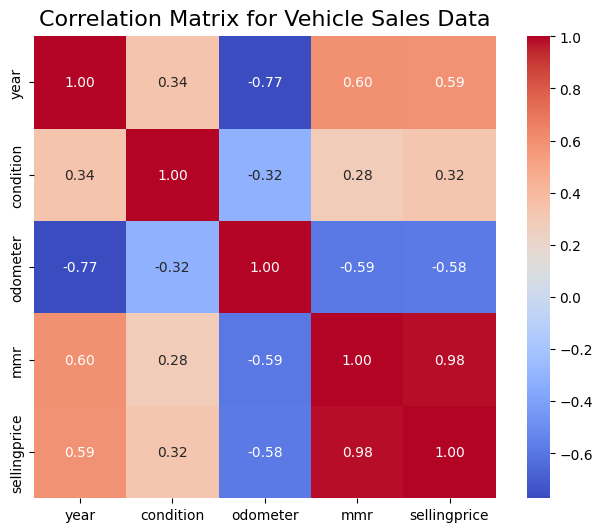

In [ ]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title('Correlation Matrix for Vehicle Sales Data', fontsize=16, pad=8)
plt.show()

**Subset Data to vehicles with no less than 2,000 miles (classify as used vehicle)**

The goal of the project is to fit a ML model for used vehicles. From the variables given in the data set, used vehicles were determined based on the odometer reading. From consulting a car salesman, it was decided for this project that cars with 2,000 miles or more are classified as a used vehicle.

In [ ]:
df_used = df[df["odometer"] >= 2000].copy()

df_used.head()

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,Thu Dec 18 2014 12:30:00 GMT-0800 (PST)
5,2015,Nissan,Altima,2.5 S,Sedan,automatic,1n4al3ap1fn326013,ca,1.0,5554.0,gray,black,enterprise vehicle exchange / tra / rental / t...,15350.0,10900.0,Tue Dec 30 2014 12:00:00 GMT-0800 (PST)


A histogram is displayed of the condition variable. There is a clear separation between 0-10 and the rest of the data. This is because cars sold at auction sell on a 1-5 scale, while insurances grade cars more on a 10-49 scale.

<Axes: >

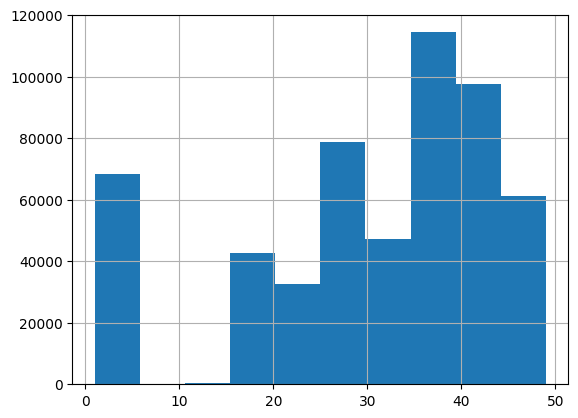

In [ ]:
df_used['condition'].hist()

From our understanding, vehicles rated 1 on an auction scale are very similar to vehicles rated between 10-19 on the insurance scale (heavy damage). This applies all the way up to 5, which is similar to a nearly perfect vehicle (49). The summary statistics are compared to see if this holds.

In [ ]:
#Saves the counts of condition groups 1 - 5
stats_1_5 = (
    df_used[df_used["condition"].isin([1.0, 2.0, 3.0, 4.0, 5.0])]
    .groupby("condition")["sellingprice"]
    .agg(Count="count", Mean="mean", Median="median")
    .round(2)
    .reset_index()
)

#Summary statistics for the 10.0 - 49.0 scale (grouped by decile)
df_10_49 = df_used[(df_used["condition"] >= 10.0) & (df["condition"] <= 49.0)].copy()


def assign_decile(val):
    if 10 <= val <= 19:
        return "10-19"
    elif 20 <= val <= 29:
        return "20-29"
    elif 30 <= val <= 39:
        return "30-39"
    elif 40 <= val <= 49:
        return "40-49"
    return None


df_10_49["condition_decile"] = df_10_49["condition"].apply(assign_decile)

stats_10_49 = (
    df_10_49.groupby("condition_decile")["sellingprice"]
    .agg(Count="count", Mean="mean", Median="median")
    .round(2)
    .reset_index()
)

# Display results
print("--- 1.0 to 5.0 Scale ---")
print(stats_1_5)

print("\n--- 10.0 to 49.0 Scale (Deciles) ---")
print(stats_10_49)

/tmp/ipykernel_2292/1637643900.py:11: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_10_49 = df_used[(df_used["condition"] >= 10.0) & (df["condition"] <= 49.0)].copy()


--- 1.0 to 5.0 Scale ---
   condition  Count      Mean   Median
0        1.0   7022   3990.23   1800.0
1        2.0  20374   5740.12   3800.0
2        3.0  10743  12307.87  11700.0
3        4.0  19800  17672.34  16400.0
4        5.0  10348  24385.32  22000.0

--- 10.0 to 49.0 Scale (Deciles) ---
  condition_decile   Count      Mean   Median
0            10-19   43303   5062.67   3600.0
1            20-29  111414   9267.31   8000.0
2            30-39  161505  13939.72  12400.0
3            40-49  158938  19391.17  17200.0


The means and medians are similar among the scales. This may lead to a manipulation to combine the auction vehicles (1-5) into the same scale as the insurance vehicles (10 - 49).

Next, a quick summary statistics for all variables. This helps give a quick look at all the data and any potential outliers/typos. For example, there is at least one vehicle listed with 999,999 miles, which may indicate a typo since vehicles listed as such either don't have a true mileage count or have an electrical malfunction displaying this number.

In [ ]:
df_used.describe(include = "all")

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
count,555078.000000,544858,544779,544514,541983,490228,555078,555078,543459.000000,555078.000000,554364,554364,555078,555066.000000,555066.000000,555066
unique,NaN,96,971,1956,86,2,546771,38,NaN,NaN,20,17,14151,NaN,NaN,3683
top,NaN,Ford,Altima,Base,Sedan,automatic,wbanv13588cz57827,fl,NaN,NaN,black,black,nissan-infiniti lt,NaN,NaN,Tue Feb 10 2015 01:30:00 GMT-0800 (PST)
freq,NaN,93136,19249,55412,198022,472900,5,82325,NaN,NaN,110306,242710,19653,NaN,NaN,5313
mean,2010.037153,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.739977,68767.330361,NaN,NaN,NaN,13732.947794,13585.609845,NaN
std,3.952505,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.331082,53289.060429,NaN,NaN,NaN,9592.798679,9655.238797,NaN
min,1982.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,2001.000000,NaN,NaN,NaN,25.000000,1.000000,NaN
25%,2007.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.000000,28786.000000,NaN,NaN,NaN,7100.000000,6900.000000,NaN
50%,2012.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.000000,52680.000000,NaN,NaN,NaN,12250.000000,12100.000000,NaN
75%,2013.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.000000,99445.750000,NaN,NaN,NaN,18300.000000,18200.000000,NaN


The NA values are listed for each column. There are more missing values for data related to the vehicle detail (transmission, make, model). These observations may be removed since these values cannot be accurately imputed.

In [ ]:
print(df_used.isna().sum())

year                0
make            10220
model           10299
trim            10564
body            13095
transmission    64850
vin                 0
state               0
condition       11619
odometer            0
color             714
interior          714
seller              0
mmr                12
sellingprice       12
saledate           12
dtype: int64


It was determined to remove observations with an odometer reading of 999,999 as this is used as a placeholder to signify a missing value or there is a glitch with the vehicle.

In [ ]:
#Remove observations with listed odometer of 999,999
df_used = df_used[df_used['odometer'] != 999999].copy()

The histograms of selling price and odometer are viewed again to see the impact of the change on the data. There doesn't appear to be a noticeable change to the data distribution.

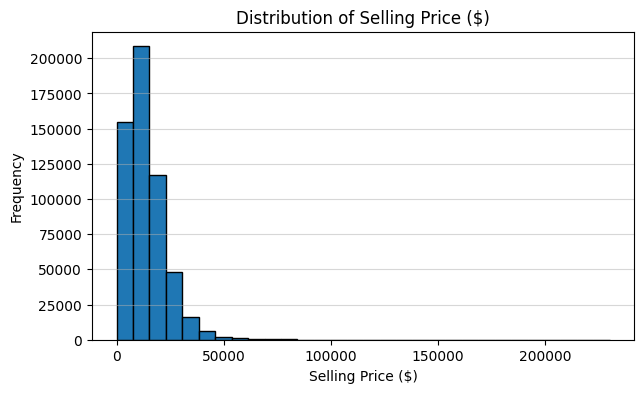

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(df_used['sellingprice'], bins = 30, edgecolor='black')
plt.title('Distribution of Selling Price ($)')
plt.xlabel('Selling Price ($)')
plt.ylabel('Frequency')
plt.ticklabel_format(style = "plain", axis = "both")
plt.grid(axis='y', alpha=0.5)
plt.show()

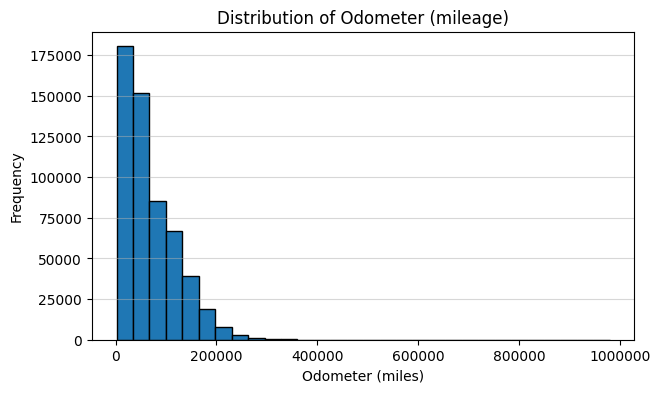

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(df_used['odometer'], bins = 30, edgecolor='black')
plt.title('Distribution of Odometer (mileage)')
plt.xlabel('Odometer (miles)')
plt.ylabel('Frequency')
plt.ticklabel_format(style = "plain", axis = "both")
plt.grid(axis='y', alpha=0.5)
plt.show()

Due to the right-skew in the selling price and odometer variables, both variables were log-transformed and their distributions were displayed to determine if a log-transform better normalizes the data.

In [ ]:
df_used["log_sellingprice"] = np.log(df_used["sellingprice"])
df_used["log_odometer"] = np.log(df_used["odometer"])

The histograms below show the data is more normalized, but it may be difficult to interpret and back-transform log-transformed data.

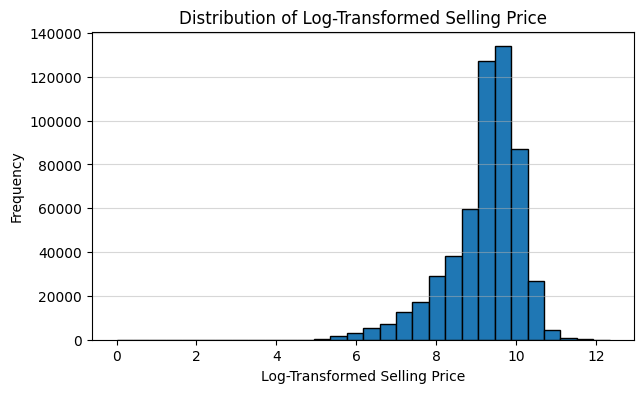

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(df_used['log_sellingprice'], bins = 30, edgecolor='black')
plt.title('Distribution of Log-Transformed Selling Price')
plt.xlabel('Log-Transformed Selling Price')
plt.ylabel('Frequency')
plt.ticklabel_format(style = "plain", axis = "both")
plt.grid(axis='y', alpha=0.5)
plt.show()

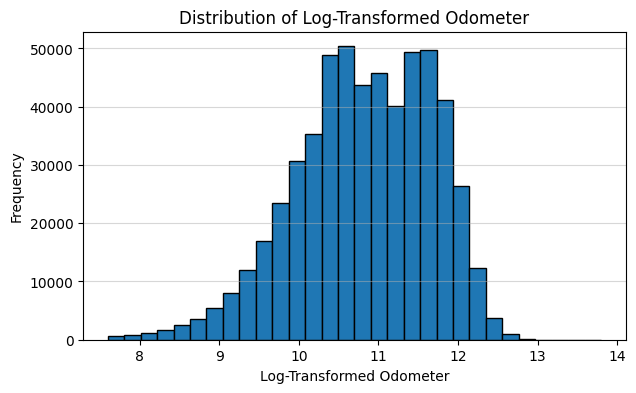

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(df_used['log_odometer'], bins = 30, edgecolor='black')
plt.title('Distribution of Log-Transformed Odometer')
plt.xlabel('Log-Transformed Odometer')
plt.ylabel('Frequency')
plt.ticklabel_format(style = "plain", axis = "both")
plt.grid(axis='y', alpha=0.5)
plt.show()

A quick scatter plot of odometer vs. selling price and log-odometer vs. selling price. There doesn't appear to be an obvious linear relationship among these two variables - there may be a negative-log shape, but difficult to tell.

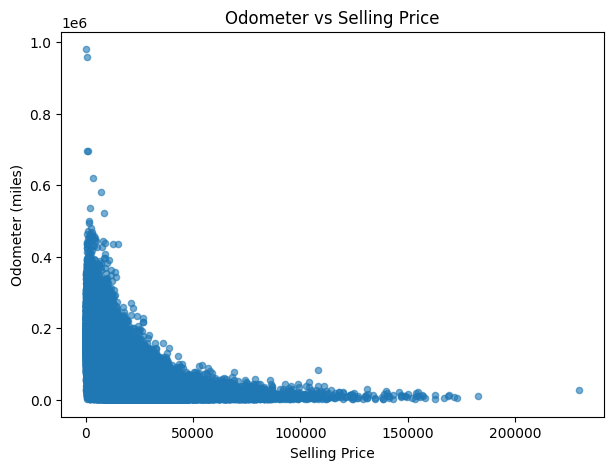

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(df_used['sellingprice'].to_numpy(), df_used['odometer'].to_numpy(), alpha=0.6, s=20)
plt.xlabel('Selling Price')
plt.ylabel('Odometer (miles)')
plt.title("Odometer vs Selling Price")
plt.show()

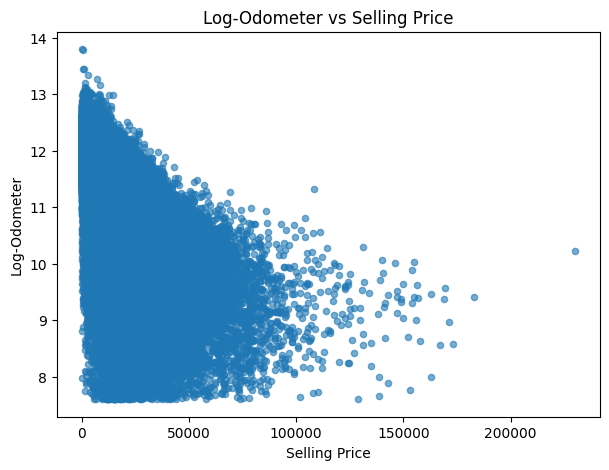

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(df_used['sellingprice'].to_numpy(), df_used['log_odometer'].to_numpy(), alpha=0.6, s=20)
plt.xlabel('Selling Price')
plt.ylabel('Log-Odometer')
plt.title("Log-Odometer vs Selling Price")
plt.show()

The correlation matrix is also viewed again. The relationship between selling price and odometer had a minimal change (-0.59 to -0.60). The biggest change was for the relationship between year and odometer (-0.77 to -0.80).

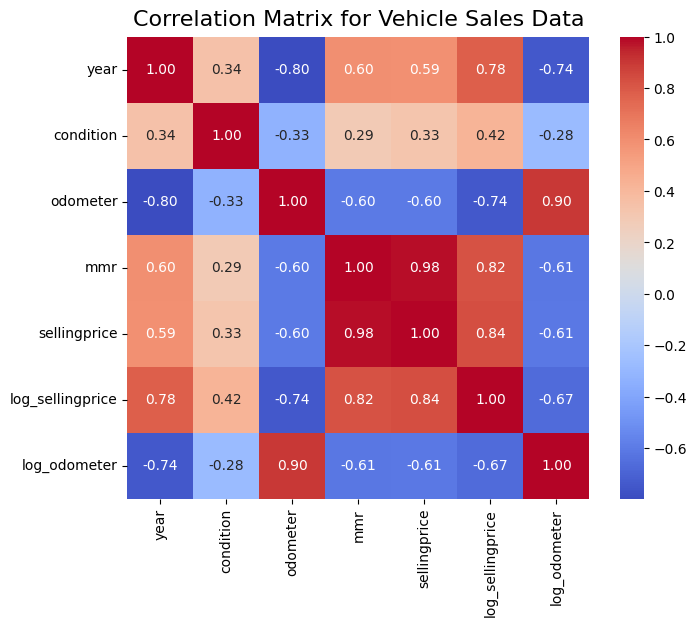

In [ ]:
correlation_matrix_used = df_used.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix_used, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title('Correlation Matrix for Vehicle Sales Data', fontsize=16, pad=8)
plt.show()

**Condition Grouping**

As discussed before, the conditions may be grouped into various degrees (below average, average, great, etc.). This is attempted to see if condition will have any impact on used vehicle selling price.

In [ ]:
#Group the condition variable.
df_used["condition_normalized"] = df_used["condition"].apply(
    lambda x: x * 10 if x <= 5.0 else x
)
bins = [0, 10, 20, 30, 40, 50]
group_labels = ["Poor", "Below Average", "Average", "Very Good", "Great"]

# Create the grouped condition column
df_used["condition_group"] = pd.cut(
    df_used["condition_normalized"], bins=bins, labels=group_labels, right=True
)

The data is viewed once again to see if the manipulations worked.

I changed the upper condition bin from 49 to 50 because condition values of 5.0 are converted to 50 during normalization. If the bin ended at 49, because those vehicles would fall outside the range and become missing values. 50 makes sure the highest condition vehicles are correctly included in this case “Great” category.

In [ ]:
df_used.head()

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate,log_sellingprice,log_odometer,condition_normalized,condition_group
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST),9.975808,9.719505,50.0,Great
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST),9.975808,9.147720,50.0,Great
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,Thu Jan 29 2015 04:30:00 GMT-0800 (PST),10.230991,9.566755,41.0,Great
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,Thu Dec 18 2014 12:30:00 GMT-0800 (PST),11.112448,7.878913,43.0,Great
5,2015,Nissan,Altima,2.5 S,Sedan,automatic,1n4al3ap1fn326013,ca,1.0,5554.0,gray,black,enterprise vehicle exchange / tra / rental / t...,15350.0,10900.0,Tue Dec 30 2014 12:00:00 GMT-0800 (PST),9.296518,8.622274,10.0,Poor


A quick histogram is created to see the distribution among the created condition groups.

<Axes: xlabel='condition_group'>

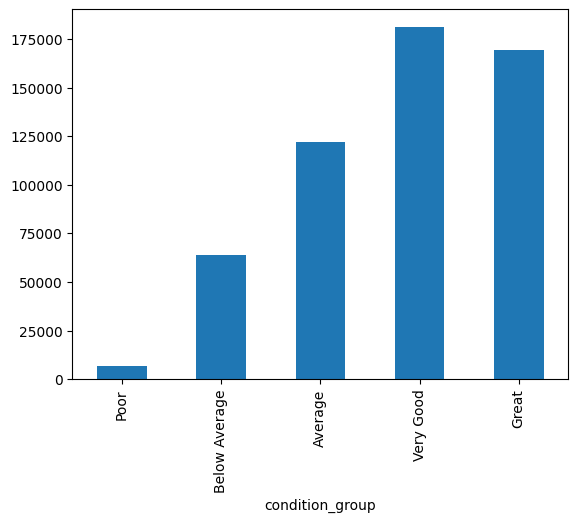

In [ ]:

#Set the condition order
condition_order = [
    "Poor",
    "Below Average",
    "Average",
    "Very Good",
    "Great"]
#Converts the column to an ordered categorical variable
df_used["condition_group"] = pd.Categorical(
df_used["condition_group"], categories=condition_order, ordered=True)
#Prints the bar chart of the condition groups in order.
df_used["condition_group"].value_counts().loc[condition_order].plot(
    kind="bar")

**Summary Statistics and Counts**

Summary statistics and counts are useful in the identification of missing/corrupted observations as well as potential groupings for categorical variables.

A quick summary statistic to see if the conditional grouping makes sense based on condition type. From the summary, the grouping seems to make sense with poor conditioned vehicles having the lowest selling price and vehicles in great condition having the highest selling price.

In [ ]:
def iqr(x):
  return x.quantile(0.75) - x.quantile(0.25)

condition_stats = df_used.groupby("condition_group")["sellingprice"].agg(Median = "median", Mean = "mean", IQR = iqr, Count = "count").reset_index()

print(condition_stats.sort_values(by = "Mean", ascending = False))

  condition_group   Median          Mean      IQR   Count
4           Great  17500.0  19696.446593  10900.0  169286
3       Very Good  12800.0  14347.424326   8700.0  181304
2         Average   8300.0   9535.334671   8500.0  122147
1   Below Average   3600.0   5280.852241   5750.0   63651
0            Poor   1800.0   4001.187464   5700.0    6988


/tmp/ipykernel_2292/1230179609.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  condition_stats = df_used.groupby("condition_group")["sellingprice"].agg(Median = "median", Mean = "mean", IQR = iqr, Count = "count").reset_index()


Below are the value counts for the interior color. There appear to be unknown interior color ("-"). In addition, there appear to be several rare interior colors (those with less than 500 observations). These can be grouped into an "other" category.

In [ ]:
df_used['interior'].value_counts()

,count
interior,
black,242692
gray,177477
beige,59405
tan,43830
—,16791
brown,8569
red,1330
blue,1128
silver,1092


Below are the total counts for the vehicle color. Like the interior counts, there appear to be several rare colors (less than 500 observations). These can be grouped into an "other" category.

In [ ]:
df_used['color'].value_counts()

,count
color,
black,110294
white,105926
silver,82904
gray,82339
blue,50789
red,43204
—,24520
green,11274
gold,11250


A quick proportion of automatic vs. manual transmissions. This highlights the large disparity between the two types, which is not surprising since most vehicles in the United States have automatic transmissions.


In [ ]:
df_used['transmission'].value_counts(normalize = True)

,proportion
transmission,
automatic,0.964653
manual,0.035347


Basic summary statistics were created for each state, including median, mean, IQR, and total count. From this plot, it was noted there are Canadian provinces in the data (AB, ON, NS, QC). Since the goal is to create a ML model for used vehicles in the United States, these observations will be removed.

In [ ]:
def iqr(x):
  return x.quantile(0.75) - x.quantile(0.25)

state_stats = df_used.groupby("state")["sellingprice"].agg(Median = "median", Mean = "mean", IQR = iqr, Count = "count").reset_index()

print(state_stats.sort_values(by = "Median", ascending = False))

   state   Median          Mean      IQR  Count
26    on  18300.0  17789.529102  13000.0   3419
32    tn  16000.0  17002.272894  11800.0  20781
4     co  14500.0  15869.157969   9800.0   7761
28    pa  14200.0  15927.457877   9800.0  53617
8     il  13800.0  14770.877948   9000.0  23277
13    mi  13800.0  14866.779708  11700.0  15425
22    nv  13500.0  15109.646563  11500.0  12568
15    mo  13200.0  14465.698381  10000.0  15934
36    wa  13200.0  13999.872042  11300.0   7354
24    oh  12500.0  14322.566415  12200.0  21343
5     fl  12500.0  13834.898922  11300.0  82313
14    mn  12500.0  13680.896846   9600.0   9384
37    wi  12300.0  14001.935504  12100.0   9799
3     ca  12200.0  14454.838180  12300.0  72587
19    nj  12200.0  13561.014086  10300.0  27617
7     hi  11750.0  12143.393148   9000.0   1226
33    tx  11700.0  13216.682091  11050.0  45557
18    ne  11500.0  12571.408046   9000.0   4002
6     ga  11400.0  12888.703266  10900.0  34573
30    qc  11100.0  13296.578100  14100.0

Summary statistics created and grouped by vehicle make. This shows the 5 most expensive vehicle makes (Rolls-Royce, Ferrari) and the 5 cheapest vehicle makes (Oldsmobile, Daewoo). As expected, there is a large spread in selling price among vehicle makes.

In [ ]:
make_stats = df_used.groupby("make")["sellingprice"].agg(Median = "median", Mean = "mean", IQR = iqr, Count = "count").reset_index()

print(make_stats.sort_values(by = "Median", ascending = False))

           make    Median           Mean      IQR  Count
42  Rolls-Royce  149800.0  153488.235294  16000.0     17
12      Ferrari  124000.0  127210.526316  24500.0     19
25  Lamborghini  113000.0  112625.000000   7125.0      4
53    airstream   71000.0   71000.000000      0.0      1
48        Tesla   65000.0   66702.380952  11000.0     21
..          ...       ...            ...      ...    ...
63          dot     500.0     500.000000      0.0      1
86   oldsmobile     500.0     680.263158    500.0     19
16          Geo     400.0     528.947368    237.5     19
66   ford truck     400.0     483.333333    175.0      3
9        Daewoo     300.0     400.000000    150.0      3

[96 rows x 5 columns]


Quick summary statistics based on vehicle model. There are over 970 vehicle models with a large spread in selling price. Model may not be the best predictor since it is highly specific and may cause the model to crash when dummy-coding all the types.

In [ ]:
model_stats = df_used.groupby("model")["sellingprice"].agg(Median = "median", Mean = "mean", IQR = iqr, Count = "count").reset_index()

print(model_stats.sort_values(by = "Median", ascending = False))

                   model    Median           Mean       IQR  Count
32            458 Italia  183000.0  183000.000000      0.00      1
606           SLS AMG GT  156500.0  156500.000000      0.00      1
291          Flying Spur  154000.0  154000.000000    750.00      2
337                Ghost  149800.0  153488.235294  16000.00     17
864                   i8  138500.0  140000.000000   2250.00      3
..                   ...       ...            ...       ...    ...
570              Regency     300.0     300.000000      0.00      1
413              Leganza     300.0     300.000000      0.00      1
735       Windstar Cargo     262.5     281.250000     43.75      4
235  Eighty-Eight Royale     250.0     433.333333    275.00      3
502                Paseo     150.0     150.000000      0.00      1

[971 rows x 5 columns]


A quick count of the various vehicle colors. There are some rare colors that can affect the model (lime, pink), so it was determined that vehicle colors appearing less than 1,000 times would be placed in a category labeled "other". For consistency, colors with a hyphen were replaced with the name "unknown". This will be done in the data cleaning subsection.

In [ ]:
color_counts = df_used["color"].value_counts()

print(color_counts)

color
black        108855
white        104731
silver        82167
gray          81433
blue          50336
red           42742
unknown       24498
green         11212
gold          11208
beige          9021
burgundy       8904
brown          6553
orange         2007
purple         1524
off-white      1444
yellow         1247
charcoal        476
turquoise       235
pink             41
lime             15
Name: count, dtype: int64


In [ ]:
df_used["body_clean"] = df_used["body"].astype(str).str.lower().str.strip()
# Map specific body types into more generic groupings
body_mapping = {
    "g sedan": "sedan",
    "g coupe": "coupe",
    "g37 coupe": "coupe",
    "cts-v coupe": "coupe",
    "q60 coupe": "coupe",
    "koup": "coupe",
    "genesis coupe": "coupe",
    "elantra coupe": "coupe",
    "cts coupe": "coupe",
    "g convertible": "convertible",
    "g37 convertible": "convertible",
    "q60 convertible": "convertible",
    "beetle convertible": "convertible",
    "granturismo convertible": "convertible",
    "cts wagon": "wagon",
    "cts-v wagon": "wagon",
    "tsx sport wagon": "wagon",
    "e-series van": "van",
    "promaster cargo van": "van",
    "ram van": "van",
    "transit van": "van",
    "regular-cab": "regular truck",
    "club cab": "regular truck",
    "access cab": "regular truck",
    "king cab": "regular truck",
    "cab plus 4": "regular truck",
    "regular cab": "regular truck",
    "cab plus": "regular truck",
    "xtracab": "regular truck",
    "supercrew": "large truck",
    "extended cab": "large truck",
    "supercab" : "large truck",
    "crewmax cab": "large truck",
    "quad cab": "large truck",
    "extended cab": "large truck",
    "mega cab": "large truck",
    "crew cab": "large truck",
    "double cab": "large truck"

}

df_used["body_clean"] = df_used["body_clean"].replace(body_mapping)

In [ ]:
df_used['body_clean'].value_counts()

,count
body_clean,
sedan,245311
suv,141662
large truck,40900
hatchback,25656
minivan,24865
coupe,19872
wagon,15903
nan,12213
convertible,10759


In [ ]:
interior_counts = df_used["interior"].value_counts()

print(interior_counts)

interior
black        238802
gray         176386
beige         59043
tan           43809
—             16643
brown          8483
red            1312
blue           1119
silver         1090
off-white       478
purple          333
gold            315
white           245
green           243
burgundy        187
orange          143
yellow           18
Name: count, dtype: int64


In [ ]:
#Identifies rare colors
rare_interior = interior_counts[interior_counts < 1000].index

#Replaces short and long hypends with "unknown"
df_used["interior"] = df_used["interior"].replace({"—": "unknown", "-": "unknown"})

#Groups rare colors into "other"
df_used["interior_clean"] = df_used["interior"].replace(rare_interior, "other")

#Re-print the distribution of color
print(df_used["interior_clean"].value_counts())

interior_clean
black      238802
gray       176386
beige       59043
tan         43809
unknown     16643
brown        8483
other        1962
red          1312
blue         1119
silver       1090
Name: count, dtype: int64


**Data Cleaning & Mapping**

Based on the summary statistics and counts, there is data present from Canadian provinces, which can cause issues in the prediction of used vehicle sales in the United Staets.

As stated, four Canadian provinces need to be removed from the data and are done so below.

In [ ]:
canadian_provinces = ["ab", "on", "ns", "qc"]

# Keep only rows where 'state' is NOT in the list
df_used = df_used[
    ~df_used["state"].astype(str).str.lower().isin(canadian_provinces)
].copy()

In [ ]:
df_used.describe()

,year,condition,odometer,mmr,sellingprice,log_sellingprice,log_odometer,condition_normalized
count,549362.000000,537945.000000,549362.000000,549350.000000,549350.000000,549350.000000,549362.000000,537945.000000
mean,2010.025939,30.725723,68579.141116,13713.520433,13566.027877,9.207500,10.820551,34.188183
std,3.956483,13.299736,52084.140558,9589.333447,9652.150987,0.913143,0.854265,9.437624
min,1982.000000,1.000000,2001.000000,25.000000,1.000000,0.000000,7.601402,10.000000
25%,2007.000000,24.000000,28866.000000,7100.000000,6900.000000,8.839277,10.270420,27.000000
50%,2012.000000,35.000000,52666.000000,12250.000000,12100.000000,9.400961,10.871725,36.000000
75%,2013.000000,41.000000,99310.000000,18250.000000,18100.000000,9.803667,11.506002,42.000000
max,2015.000000,49.000000,980113.000000,182000.000000,230000.000000,12.345835,13.795423,50.000000


Checks the unique values of each State. Four Canadian provinces are included in the data set (AB, ON, NS, QC). Since the project's goal is to predict and explore vehicles sold in the United States, these provinces will be removed from the data set.

In [ ]:
print(df_used["state"].unique().tolist())

['ca', 'tx', 'mn', 'az', 'wi', 'tn', 'md', 'pa', 'ne', 'nj', 'nv', 'oh', 'fl', 'mi', 'ga', 'va', 'sc', 'nc', 'in', 'il', 'co', 'mo', 'ut', 'ny', 'ma', 'pr', 'or', 'la', 'wa', 'hi', 'ok', 'ms', 'al', 'nm']


All color combinations. There are colors listed as "-", which is equivalent to being marked as "unknown". For simplicity, this color group will be renamed to "unknown".

In [ ]:
print(df_used["color"].unique().tolist())

['white', 'gray', 'black', 'red', 'silver', 'blue', 'brown', 'beige', 'burgundy', 'purple', '—', 'gold', 'yellow', 'green', 'charcoal', nan, 'orange', 'off-white', 'turquoise', 'pink', 'lime']


All unique body types of the vehicles. Since there are so many, we will combine specified body types into more generic groupings.

In [ ]:
print(df_used["body"].unique().tolist())

['SUV', 'Sedan', 'Convertible', 'Coupe', 'Wagon', 'Hatchback', 'Crew Cab', 'G Coupe', 'G Sedan', 'Elantra Coupe', 'Genesis Coupe', 'Minivan', nan, 'Van', 'Double Cab', 'CrewMax Cab', 'Access Cab', 'King Cab', 'SuperCrew', 'CTS Coupe', 'Extended Cab', 'E-Series Van', 'SuperCab', 'Regular Cab', 'G Convertible', 'Koup', 'Quad Cab', 'CTS-V Coupe', 'sedan', 'G37 Convertible', 'Club Cab', 'Xtracab', 'Q60 Convertible', 'CTS Wagon', 'convertible', 'G37 Coupe', 'Mega Cab', 'Cab Plus 4', 'Q60 Coupe', 'Cab Plus', 'Beetle Convertible', 'TSX Sport Wagon', 'Promaster Cargo Van', 'GranTurismo Convertible', 'CTS-V Wagon', 'Ram Van', 'minivan', 'suv', 'Transit Van', 'van', 'regular-cab', 'g sedan', 'g coupe', 'hatchback', 'king cab', 'supercrew', 'g convertible', 'coupe', 'crew cab', 'wagon', 'double cab', 'e-series van', 'regular cab', 'quad cab', 'g37 convertible', 'supercab', 'extended cab', 'crewmax cab', 'genesis coupe', 'access cab', 'mega cab', 'xtracab', 'beetle convertible', 'cts coupe', 'koup

Mapping the body types into more generic groupings for modeling purposes. The mapping that can be altered by other modelers is "regular truck" vs. "large truck". The truck types were researched with Google, with "regular truck" being midsize trucks and "large truck" equivalent to fullsize trucks. A future model attempt may want to arrange the body types in a different manner depending on their expertise.

A quick print of the unique body types to see if they need to be changed further.

In [ ]:
print(df_used["body_clean"].unique().tolist())

['suv', 'sedan', 'convertible', 'coupe', 'wagon', 'hatchback', 'large truck', 'minivan', 'nan', 'van', 'regular truck']


A quick count for each body type. There are mostly sedans and SUVs, with regular trucks and vans being the more rare vehicle body types in the data set.

In [ ]:
#Replaces short and long hypends with "unknown"
df_used["color"] = df_used["color"].replace({"—": "unknown", "-": "unknown"})

#Identifies rare colors
rare_colors = color_counts[color_counts < 1000].index

#Groups rare colors into "other"
df_used["color_clean"] = df_used["color"].replace(rare_colors, "other")

#Re-print the distribution of color
print(df_used["color_clean"].value_counts())

color_clean
black        108855
white        104731
silver        82167
gray          81433
blue          50336
red           42742
unknown       24498
green         11212
gold          11208
beige          9021
burgundy       8904
brown          6553
orange         2007
purple         1524
off-white      1444
yellow         1247
other           767
Name: count, dtype: int64


Viewing the different Make types. Some are referring to the same vehicle make (ford vs. ford truck). These will be combined into the same grouping

In [ ]:
print(df_used["make"].unique().tolist())

['Kia', 'Volvo', 'BMW', 'Nissan', 'Chevrolet', 'Audi', 'Ford', 'Hyundai', 'Buick', 'Cadillac', 'Acura', 'Lexus', 'Infiniti', 'Jeep', 'Mercedes-Benz', 'Mitsubishi', 'Mazda', 'MINI', 'Land Rover', 'Lincoln', 'lincoln', 'Jaguar', 'Volkswagen', 'Toyota', 'Subaru', 'Scion', 'Porsche', nan, 'bmw', 'Dodge', 'FIAT', 'Chrysler', 'ford', 'Ferrari', 'Honda', 'GMC', 'mitsubishi', 'Ram', 'smart', 'chevrolet', 'Bentley', 'chrysler', 'pontiac', 'Pontiac', 'Saturn', 'Maserati', 'Mercury', 'HUMMER', 'landrover', 'cadillac', 'land rover', 'mercedes', 'mazda', 'toyota', 'lexus', 'gmc truck', 'honda', 'nissan', 'porsche', 'Saab', 'Suzuki', 'dodge', 'subaru', 'Oldsmobile', 'oldsmobile', 'hyundai', 'jeep', 'Isuzu', 'dodge tk', 'Geo', 'acura', 'volkswagen', 'suzuki', 'kia', 'Rolls-Royce', 'gmc', 'maserati', 'mazda tk', 'mercury', 'audi', 'buick', 'mercedes-b', 'Daewoo', 'chev truck', 'ford tk', 'plymouth', 'vw', 'Plymouth', 'ford truck', 'Tesla', 'airstream', 'dot', 'Aston Martin', 'Fisker', 'Lamborghini', '

All text is lower cased for easier cleaning. This will also naturally combine some groups (Ford & ford).

In [ ]:
df_used["make_clean"] = df_used["make"].astype(str).str.lower().str.strip()

In [ ]:
make_mapping = {
  "mercedes-benz": "mercedes",
  "mercedes-b": "mercedes",
  "chev truck": "chevrolet",
  "dodge tk": "dodge",
  "ford tk": "ford",
  "ford truck": "ford",
  "gmc truck": "gmc",
  "hyundai tk": "hyundai",
  "mazda tk": "mazda",
  "vw": "volkswagen"
}

df_used["make_clean"] = df_used["make_clean"].replace(make_mapping)

A quick printout of unique vehicle makes to see if there are any that should be grouped together.

In [ ]:
df_used["make_clean"] = df_used["make_clean"].astype(str).str.lower().str.strip()

print(df_used["make_clean"].unique().tolist())

NameError: name 'df_used' is not defined

A quick count of vehicle makes. The data set contains a lot of Ford and Chevrolet vehicles, with some very rare vehicle makes such as an Airstream RV and luxurious vehicles (Lamborghini and Lotus).

In [ ]:
df_used['make_clean'].value_counts()

NameError: name 'df_used' is not defined

Due to their rarity and uniqueness, the Airstream RV and Daewoo vehicles were removed. The dot vehicle came back as an unknown make when searching on Google, so it was removed from the data set.

In [ ]:
makes_to_drop = ["airstream", "dot", "daewoo"]
df_used = df_used[~df_used["make_clean"].isin(makes_to_drop)].copy()

NameError: name 'df_used' is not defined

Like the vehicle color, the vehicle interior had some rare colors. These rare occurences (less than 1,000) were combined into a category labeled "other".

In [ ]:
interior_counts = df_used["interior"].value_counts()

print(interior_counts)

NameError: name 'df_used' is not defined

**Statistical Modeling**

After EDA and data cleaning, a multiple linear regresssion model is created to better understand the significant factors in the prediction of selling price. After a linear regression model is created, a ML model is passed on the same variables, which can be further tweaked by the various loss functions and tuning parameters.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error
import statsmodels.api as sm #Linear regression -- non-ML
import statsmodels.formula.api as smf #Writes Linear Regression formula
import patsy
from statsmodels.stats.outliers_influence import variance_inflation_factor

The code below keeps all of the variables that are explored in the modeling process.

In [ ]:
df_used_model = df_used[['sellingprice', 'year', 'make_clean', 'model', 'trim', 'body_clean', 'transmission',
                         'state', 'condition', 'odometer', 'log_odometer', 'condition_group', 'color', 'interior', 'color_clean', 'interior_clean']]


The first model is created, keeping log-odometer at first. The model determined state was not statistically significant, so it was removed from the model and re-run.

In [ ]:
formula = "sellingprice ~ year + log_odometer + C(make_clean) + C(body_clean) + C(transmission) + C(condition_group) + C(state) + C(color) + C(interior)"

model = smf.ols(formula=formula, data=df_used_model.dropna()).fit()
print(model.summary())

NameError: name 'df_used_model' is not defined

The second model performed about the same as the first one, which highlights that state information did not contribute much to the model's performance.

In [ ]:
formula2 = "sellingprice ~ year + log_odometer + C(make_clean) + C(body_clean) + C(condition_group) + C(transmission) + C(color) + C(interior)"

model2 = smf.ols(formula=formula2, data=df_used_model.dropna()).fit()
print(model2.summary())

For interpretability purposes, the log-odometer variable was changed back to its normal configuration and re-run. The adjusted R² dropped a little, but not significantly. This model would be better for interpretability.

In [ ]:
formula3 = "sellingprice ~ year + odometer + C(make_clean) + C(body_clean) + C(condition_group) + C(transmission) + C(color) + C(interior)"

model3 = smf.ols(formula=formula3, data=df_used_model.dropna()).fit()
print(model3.summary())

                            OLS Regression Results                            
Dep. Variable:           sellingprice   R-squared:                       0.703
Model:                            OLS   Adj. R-squared:                  0.703
Method:                 Least Squares   F-statistic:                 1.087e+04
Date:                Fri, 02 Oct 2026   Prob (F-statistic):               0.00
Time:                        06:41:58   Log-Likelihood:            -4.6802e+06
No. Observations:              469266   AIC:                         9.361e+06
Df Residuals:                  469163   BIC:                         9.362e+06
Df Model:                         102                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

/tmp/ipykernel_2292/3579478104.py:3: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model3 = smf.ols(formula=formula3, data=df_used_model.dropna()).fit()


The next model used the vehicle color and interior groupings created above. Adjusted R² and AIC did not change whatsoever, which may be because the rare interior and exterior colors did not have a significant impact on the model. For now, the updated color and interior groupings were left in the model for less dummy-encoded variables in the final model. This can be discussed further if warranted.

In [ ]:
formula4 = "sellingprice ~ year + odometer + C(make_clean) + C(body_clean) + C(condition_group) + C(transmission) + C(color_clean) + C(interior_clean)"

model4 = smf.ols(formula=formula4, data=df_used_model.dropna()).fit()
print(model4.summary())

# RMSE for Static Formula 4
rmse4 = np.sqrt(np.mean(model4.resid**2))
print("RMSE:", rmse4)

/tmp/ipykernel_2292/4022452907.py:3: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model4 = smf.ols(formula=formula4, data=df_used_model.dropna()).fit()


                            OLS Regression Results                            
Dep. Variable:           sellingprice   R-squared:                       0.703
Model:                            OLS   Adj. R-squared:                  0.703
Method:                 Least Squares   F-statistic:                 1.205e+04
Date:                Fri, 02 Oct 2026   Prob (F-statistic):               0.00
Time:                        06:56:58   Log-Likelihood:            -4.6803e+06
No. Observations:              469266   AIC:                         9.361e+06
Df Residuals:                  469173   BIC:                         9.362e+06
Df Model:                          92                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

In [ ]:
#df_used.to_csv("/content/drive/My Drive/cleaned_car_prices.csv", index=False)

In [ ]:
#df_used.to_csv("/content/drive/Stat585/cleaned_car_prices.csv", index=False)

The GVIF was run in R to determine multicollinearity among the variables. The values to note are the adjusted GVIF values in the far right column. GVIF scales the values on the left-hand side by the individual variable's degrees of freedom, which assists in comparing categorical variables to continuous variables and identify multicollinearity. All values are below 2.25, which indicates there is no multicollinearity in the model.

In [ ]:
gvif_data = {
    "Variable": [
        "year",
        "log_odometer",
        "factor(make_clean)",
        "factor(body_clean)",
        "factor(condition_group)",
        "factor(transmission)",
        "factor(color_clean)",
        "factor(interior_clean)",
    ],
    "GVIF": [
        3.419318,
        3.054783,
        18.015363,
        14.044986,
        1.823019,
        1.126210,
        2.050022,
        2.450108,
    ],
    "Df": [1, 1, 53, 10, 5, 2, 20, 9],
    "GVIF^(1/(2*Df))": [
        1.849140,
        1.747794,
        1.027651,
        1.141238,
        1.061889,
        1.030160,
        1.018108,
        1.051045,
    ],
}
#Save as a DataFrame
df_gvif = pd.DataFrame(gvif_data)
#Remove the row indexes and set the index to the Variable name
df_gvif_indexed = df_gvif.set_index("Variable")

#Displays the DataFrame
display(df_gvif_indexed)

,GVIF,Df,GVIF^(1/(2*Df))
Variable,,,
year,3.419318,1,1.849140
log_odometer,3.054783,1,1.747794
factor(make_clean),18.015363,53,1.027651
factor(body_clean),14.044986,10,1.141238
factor(condition_group),1.823019,5,1.061889
factor(transmission),1.126210,2,1.030160
factor(color_clean),2.050022,20,1.018108
factor(interior_clean),2.450108,9,1.051045


Before running in R, the code below allowed us to view the VIF for the numeric variables.

In [ ]:
df_sample = df_used_model.sample(n=20000, random_state=42)

y_matrix, X_matrix = patsy.dmatrices(formula2, data=df_used, return_type="dataframe")

key_vars = ["Intercept", "year", "log_odometer"]
vif_results = []

for var in key_vars:
    col_idx = X_matrix.columns.get_loc(var)
    vif_val = variance_inflation_factor(X_matrix.values, col_idx)
    vif_results.append({"Variable": var, "VIF": round(vif_val, 2)})

print(pd.DataFrame(vif_results))

/tmp/ipykernel_2292/3155370313.py:10: UserWarning: The design matrix is poorly conditioned (condition number=3.23e+16). VIF calculations may be numerically unstable.
  vif_val = variance_inflation_factor(X_matrix.values, col_idx)
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


       Variable   VIF
0     Intercept  1.00
1          year  2.90
2  log_odometer  2.55


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


The static model performed well, however it is difficult to conclude if a static model is best without the proper scalability and optimization of coefficients based on the error terms. A machine learning (ML) model is able to scale the model quite easily, as well as optimize coefficients via Stochastic Gradient Descent.

# **Training Baseline ML Model**

Training a machine learning model to predict the selling price of used vehicles.We are using the same variables from the most recent regression model so the results can be compared. Selling price is the response variable and the remaining variables are used as predictors.

In [ ]:
#Identifying our that will be used for the ML model
ml_data = df_used_model[
    [
        'sellingprice',
        'year',
        'odometer',
        'make_clean',
        'body_clean',
        'condition_group',
        'transmission',
        'color_clean',
        'interior_clean'
    ]
].dropna()

#spliting the predictors and response variable
X = ml_data.drop(columns=['sellingprice'])
y = ml_data['sellingprice']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (479798, 8)
y shape: (479798,)


80% of the data is used to train the model and the remaining 20% is kept separate to test how well the model performs on data it has not seen before. A random state of 42 is used so the same split can be reproduced.

In [ ]:
#Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 383838
Testing observations: 95960


Before training the model, we first prepare the data. We standardize the numeric variables so they are all on a similar scale. Some variables, like make, body type, condition, transmission, exterior color, and interior color, are categories instead of numbers. Since SGDRegressor only works with numbers, we use OneHotEncoder to turn each category into 0s and 1s. This allows the model to use the categorical variables without assuming that one category is higher or lower than another.

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

#Numeric variables
numeric_features = [
    'year',
    'odometer'
]

#Categorical variables
categorical_features = [
    'make_clean',
    'body_clean',
    'condition_group',
    'transmission',
    'color_clean',
    'interior_clean'
]

#Preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

SGDRegressor is used as the first model. It learns by adjusting its values to reduce prediction errors. We first test it with the default settings.

In [ ]:
#baseline ML model
baseline_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', SGDRegressor(
            random_state=42,
            max_iter=1000,
            tol=1e-3
        ))
    ]
)

#Training the model
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['year', 'odometer']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['make_clean', 'body_clean',
                                                   'condition_group',
                                                   'transmission',
                                                   'color_clean',
                                                   'interior_clean'])])),
                ('model', SGDRegressor(random_state=42))])

The baseline model is checked using training and testing R² and RMSE. We also compare the training and testing results to see how well the model works on new data.

In [ ]:
#Predictions
y_train_pred = baseline_model.predict(X_train)
y_test_pred = baseline_model.predict(X_test)

#Evaluation metrics
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("Baseline SGDRegressor Results")
print("--------------------------------")
print("Training R²:", round(train_r2, 4))
print("Testing R²:", round(test_r2, 4))
print("Test RMSE:", round(rmse, 2))

Baseline SGDRegressor Results
--------------------------------
Training R²: 0.6895
Testing R²: 0.6866
Test RMSE: 5347.62


The model performs very similar on both the training and testing data, which means there are no strong signs of overfitting. The testing R² is 0.6866, meaning the model explains about 68.7% of the changes in used car selling prices. The test RMSE is about $5,348. This means the models predictions are usually off by around 5,348. Since the model uses squared error, bigger mistakes are penalized more than smaller ones.


# **Tuning the Baseline Model**

The baseline model used the default learning rate. Next, we will try different learning rates to see if the model performs better.

For this project, we are using Formula 4 from the static linear regression model as our baseline model.

Experiment 1: Lower Learning Rate for this experiment, we lower the learning rate to 0.001. This makes the model learn in smaller steps. We want to see if this helps improve the model’s performance on the test data.

In [ ]:
#Experiment 1 - Lower learning rate
experiment1_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', SGDRegressor(
            random_state=42,
            max_iter=1000,
            tol=1e-3,
            learning_rate='constant',
            eta0=0.001
        ))
    ]
)

#Train the model
experiment1_model.fit(X_train, y_train)

#Make predictions
experiment1_train_pred = experiment1_model.predict(X_train)
experiment1_test_pred = experiment1_model.predict(X_test)

#Evaluate the model
experiment1_train_r2 = r2_score(y_train, experiment1_train_pred)
experiment1_test_r2 = r2_score(y_test, experiment1_test_pred)
experiment1_rmse = np.sqrt(
    mean_squared_error(y_test, experiment1_test_pred)
)
experiment1_mae = mean_absolute_error(
    y_test, experiment1_test_pred
)

print("Experiment 1 Results")
print("--------------------------------")
print("Training R²:", round(experiment1_train_r2, 4))
print("Testing R²:", round(experiment1_test_r2, 4))
print("Test RMSE:", round(experiment1_rmse, 2))

Experiment 1 Results
--------------------------------
Training R²: 0.6894
Testing R²: 0.6866
Test RMSE: 5348.27
Test MAE: 3530.87


Both models had almost the same R². However, Experiment 1 had slightly worse RMSE scores. This means lowering the learning rate to 0.001 did not improve the model. For now, the baseline model performs better. Regularization methods will be run to see if the performance metrics can improve based on the investigation of various learning rate sizes.

# **Regularization and Cross-Validation**

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import RidgeCV, LassoCV

We used 5-fold cross validation to test the SGDRegressor on different parts of the training data. The average R² was 0.6887 and the results from each fold were very close. This suggests that the model performs consistently and is not relying too much on one specific split of the training data.

This is an important distinction from the static model, which tests a single R² value over one train-test split, making it difficult to determine if the results will be consistent when re-testing. The cross-validation of the ML model displays more consistent and reliable results, giving confidence in continuous performance.


In [ ]:
##Shuffles the training data before creating the 5 folds

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

#R^2 scores of the 5 folds
r2_scores = cross_val_score(baseline_model, X_train, y_train, cv=kfold, scoring='r2')

print(f"R^2 scores for each fold: {r2_scores}")
print(f"Mean R^2 score: {r2_scores.mean():.4f} +/- {r2_scores.std():.4f}")

R^2 scores for each fold: [0.68787483 0.6890555  0.68634211 0.69139366 0.688822  ]
Mean R^2 score: 0.6887 +/- 0.0017


## **Ridge Regression**

We use Ridge Regression to see if it can improve the ML model. Ridge helps keep the model from putting too much weight on certain variables. We test different alpha values to see which one gives the best results.

In [ ]:
from sklearn.linear_model import Ridge

# Define the specific alpha values to test
alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 20, 100]

for alpha_val in alphas:
    print(f"\nEvaluating Ridge Regression with alpha = {alpha_val}")
    print("---------------------------------------------------")

    # Create a Ridge model within the pipeline for the current alpha
    ridge_model = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('model', Ridge(alpha=alpha_val, random_state=42))
        ]
    )

    # Train the Ridge model
    ridge_model.fit(X_train, y_train)

    # Make predictions with the Ridge model
    ridge_train_pred = ridge_model.predict(X_train)
    ridge_test_pred = ridge_model.predict(X_test)

    # Evaluate the Ridge model
    ridge_train_r2 = r2_score(y_train, ridge_train_pred)
    ridge_test_r2 = r2_score(y_test, ridge_test_pred)
    ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_test_pred))

    print("Training R²:", round(ridge_train_r2, 4))
    print("Testing R²:", round(ridge_test_r2, 4))
    print("Test RMSE:", round(ridge_rmse, 2))


Evaluating Ridge Regression with alpha = 0.0001
---------------------------------------------------
Training R²: 0.698
Testing R²: 0.6947
Test RMSE: 5278.17

Evaluating Ridge Regression with alpha = 0.001
---------------------------------------------------
Training R²: 0.698
Testing R²: 0.6947
Test RMSE: 5278.14

Evaluating Ridge Regression with alpha = 0.01
---------------------------------------------------
Training R²: 0.698
Testing R²: 0.6947
Test RMSE: 5278.18

Evaluating Ridge Regression with alpha = 0.1
---------------------------------------------------
Training R²: 0.698
Testing R²: 0.6947
Test RMSE: 5278.2

Evaluating Ridge Regression with alpha = 1
---------------------------------------------------
Training R²: 0.6979
Testing R²: 0.6946
Test RMSE: 5278.91

Evaluating Ridge Regression with alpha = 10
---------------------------------------------------
Training R²: 0.6957
Testing R²: 0.6924
Test RMSE: 5298.66

Evaluating Ridge Regression with alpha = 20
---------------------

From the results, the smaller alpha values gave almost the same results, and 0.001 worked best. When alpha got larger, the model started performing worse. This means a small amount of regularization worked better for this model, which indicates a weaker penalty on the coefficients.




## **Lasso Regression**

Next, Lasso Regression was run on the model using varoius alpha values. Lasso Regression penalizes coefficients by the sum of the absolute value of the model's coefficients, which can lead to some becoming zero and can eliminate coefficients from the model by shrinking them to zero. From the results, the best Lasso Regression model had alpha = 0.001, giving a training R² of 0.698 and a testing R² of 0.696, with an RMSE of 5,268 dollars. The Lasso regression performed slightly better than Ridge Regression, with a slightly better RMSE.

In [ ]:
alphas = [0.001, 0.01, 0.1, 1, 10, 20, 100]
# Create a LassoCV model within the pipeline
# Set max_iter for convergence, especially with larger datasets
lasso_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LassoCV(alphas=alphas, random_state=42, max_iter=1000, tol=0.01))
    ]
)

# Train the Lasso model
lasso_model.fit(X_train, y_train)

# Get the best alpha found by LassoCV
best_alpha_lasso = lasso_model.named_steps['model'].alpha_
print(f"Best alpha for Lasso Regression: {best_alpha_lasso:.4f}")

# Make predictions with the Lasso model
lasso_train_pred = lasso_model.predict(X_train)
lasso_test_pred = lasso_model.predict(X_test)

# Evaluate the Lasso model
lasso_train_r2 = r2_score(y_train, lasso_train_pred)
lasso_test_r2 = r2_score(y_test, lasso_test_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_test_pred))

print("\nLasso Regression Results")
print("--------------------------------")
print("Training R²:", round(lasso_train_r2, 4))
print("Testing R²:", round(lasso_test_r2, 4))
print("Test RMSE:", round(lasso_rmse, 2))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 314193758214.7422, tolerance: 283490064771.7725
  model = cd_fast.sparse_enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 349686378791.0596, tolerance: 283490064771.7725
  model = cd_fast.sparse_enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 349056758581.8447, tolerance: 283490064771.7725
  model = cd_fast.sparse_enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:656: Converge

Best alpha for Lasso Regression: 0.0010

Lasso Regression Results
--------------------------------
Training R²: 0.6981
Testing R²: 0.6958
Test RMSE: 5268.46


# **Conclusion**

The goal of this project was to see how well we could predict the selling price of used vehicles based on different vehicle characteristics. Our Formula 4 static regression model was used as the baseline and had an R² of 0.703, meaning it explained about 70.3% of the variation in selling price. Though this model may be more interpretable with the given output, the static model may not be the most accurate representation since the features were not scaled and an optimization process was not run.

A SGDRegressor model was run to optimize the coefficients and scale the features provided by the static model. The first SGD model had a testing R² of 0.6866 and an RMSE of about 5,348 dollars. We also tried lowering the learning rate, but the results stayed almost the same, so that change did not improve the model.

The 5 fold cross-validation gave an average R² of 0.6887, and the results from each fold were very close, meaning this showed that the model was giving consistent results across different parts of the training data.

We also tested Ridge and Lasso Regression. Ridge performed better than the original SGD model, with a testing R² of 0.6947 and an RMSE of about 5,278 dollars using an alpha of 0.001. In addition, the Lasso Regression model gave the best machine learning results, with a testing R² of 0.6958 and an RMSE of about 5,268 dollars. The best alpha for Lasso was also 0.001. However, this comes with a trade-off based on runtime efficiency. The Lasso Regression took much longer to run due to its absolute value penalty, which can take much more computing power and resources to run a large model.

Overall, our models were able to explain around 69% to 70% of the variation in used vehicle selling prices. The regularized models improved the machine learning results slightly, with Lasso performing the best out of the machine learning models we tested. This shows that the vehicle characteristics in our dataset were useful for predicting selling price, although there is still some variation that our models could not explain.